# Predictive Maintenance Failure Prediction

This notebook uses the AI4I 2020 dataset to explore whether machine operating measurements can help predict a failure. It also examines a failure-type label derived from the recorded failure indicators. The failure classes are imbalanced, so performance on the rare classes matters as well as overall accuracy.

## Load the dataset

The data is read from the UCI Machine Learning Repository. Re-running the loading cell requires an internet connection.

In [52]:
import pandas as pd

# AI4I 2020 Predictive Maintenance dataset (UCI)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00601/ai4i2020.csv"
df = pd.read_csv(url)

df.info()
display(df.head())

Dataset successfully loaded directly from UCI Repository!

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF     

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### Targets

`machine_failure` is the binary target. For the second task, the individual failure indicators are combined into a `failure_type` label.

In [53]:
# Let's check the unique combination and counts of failures
failure_cols = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
print("Failure mode columns breakdown:")
for col in failure_cols:
    if col in df.columns:
        print(f"{col} count of failures:", df[col].sum())

# Verify binary target value distribution
if 'Machine failure' in df.columns:
    print("\nBinary Target ('Machine failure') distribution:")
    print(df['Machine failure'].value_counts())

Failure mode columns breakdown:
TWF count of failures: 46
HDF count of failures: 115
PWF count of failures: 95
OSF count of failures: 98
RNF count of failures: 19

Binary Target ('Machine failure') distribution:
Machine failure
0    9661
1     339
Name: count, dtype: int64


### Clean columns and create the failure-type label

Column names are normalized to lowercase with underscores. A row is labeled `none` when there is no machine failure, assigned its active failure mode when exactly one indicator is set, and labeled `multi_failure` when several are set. Failures with no listed mode are labeled `other`.

In [54]:
# 1. Clean column names
df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_').str.replace('[', '').str.replace(']', '')
print("Cleaned columns:", list(df.columns))

# 2. Construct the multiclass target: 'failure_type'
# Let's map the failure modes to a single column
def get_failure_type(row):
    if row['machine_failure'] == 0:
        return 'none'

    # Check which failure mode is active
    failures = []
    for col in ['twf', 'hdf', 'pwf', 'osf', 'rnf']:
        if row[col] == 1:
            failures.append(col)

    if len(failures) == 0:
        # Sometimes machine_failure is 1 but no specific failure type is checked
        return 'other'
    elif len(failures) == 1:
        return failures[0]
    else:
        return 'multi_failure'

df['failure_type'] = df.apply(get_failure_type, axis=1)

print("\nMulticlass target ('failure_type') distribution:")
print(df['failure_type'].value_counts())


Cleaned columns: ['udi', 'product_id', 'type', 'air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'machine_failure', 'twf', 'hdf', 'pwf', 'osf', 'rnf']

Multiclass target ('failure_type') distribution:
failure_type
none             9661
hdf               106
pwf                80
osf                78
twf                42
multi_failure      24
other               9
Name: count, dtype: int64


### Exploratory data analysis

Check missing values, compare the numeric features with the binary target, and inspect feature distributions by failure status.

In [55]:
# 1. Check for missing values
print("Missing values in each column:")
print(df.isnull().sum())

# 2. Select numerical columns for correlation analysis
num_cols = ['air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min']

# Calculate correlation with the binary target
correlations = df[num_cols + ['machine_failure']].corr()['machine_failure'].sort_values(ascending=False)
print("\nNumerical feature correlations with 'machine_failure':")
print(correlations)

Missing values in each column:
udi                      0
product_id               0
type                     0
air_temperature_k        0
process_temperature_k    0
rotational_speed_rpm     0
torque_nm                0
tool_wear_min            0
machine_failure          0
twf                      0
hdf                      0
pwf                      0
osf                      0
rnf                      0
failure_type             0
dtype: int64

Numerical feature correlations with 'machine_failure':
machine_failure          1.000000
torque_nm                0.191321
tool_wear_min            0.105448
air_temperature_k        0.082556
process_temperature_k    0.035946
rotational_speed_rpm    -0.044188
Name: machine_failure, dtype: float64


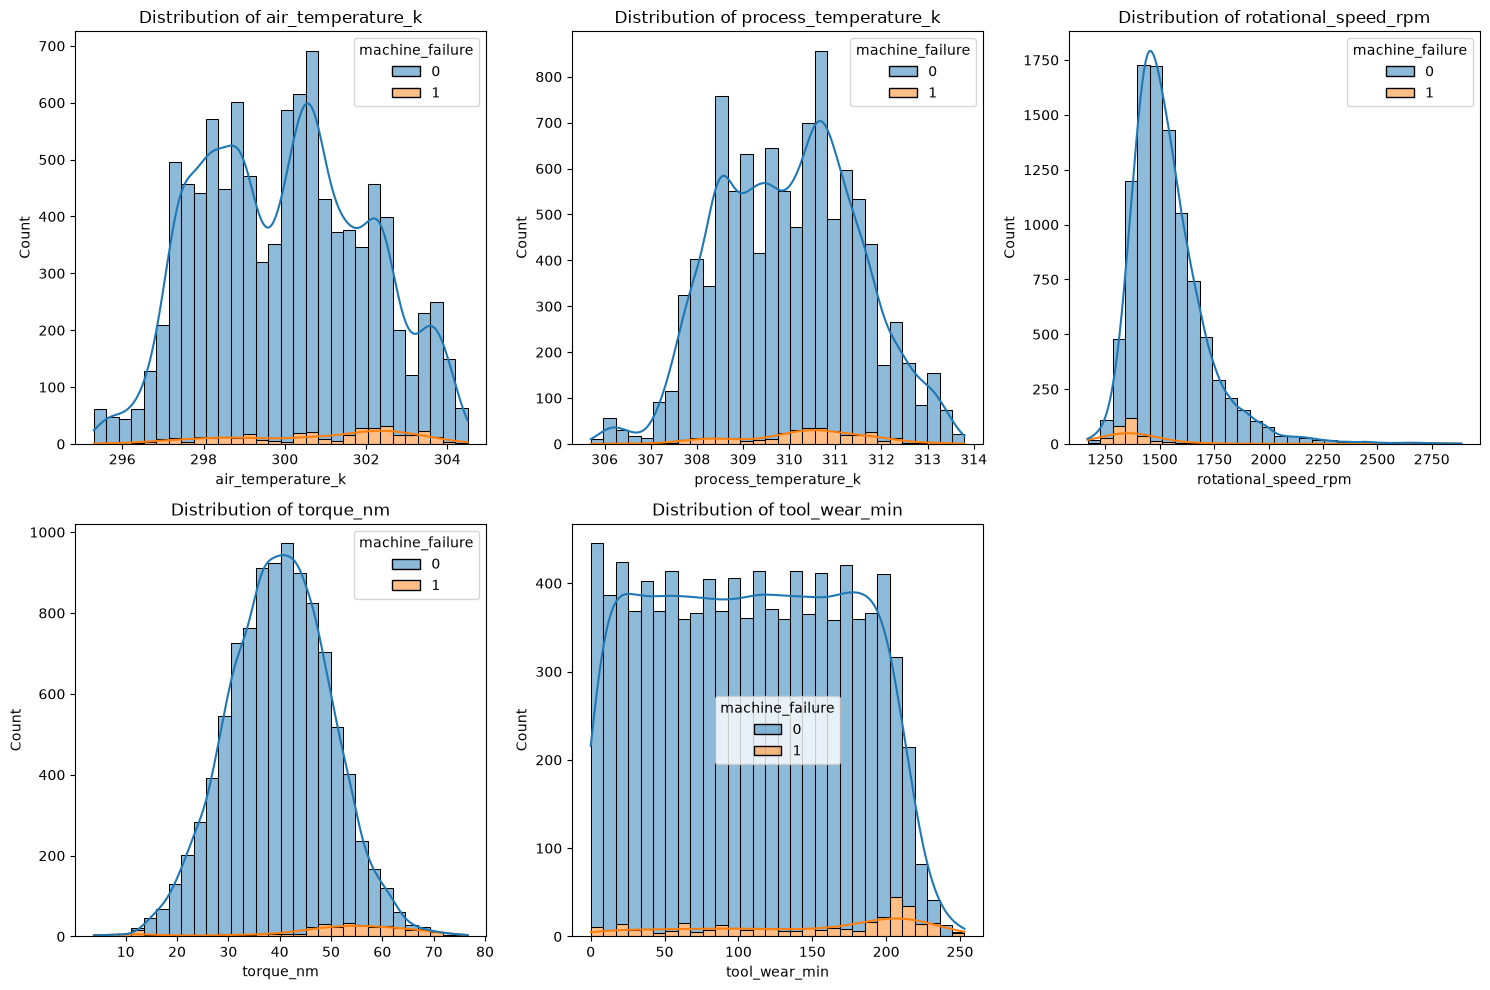

In [56]:
# 3. Visualize feature distributions
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))
for i, col in enumerate(num_cols, 1):
    plt.subplot(2, 3, i)
    sns.histplot(data=df, x=col, hue='machine_failure', kde=True, multiple='stack', bins=30)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

### Prepare features and split the data

The models use five numeric measurements and one-hot encoded product type. A stratified 60/20/20 split is created for each target. The notebook reports validation results; the held-out test splits are created but are not evaluated in the current analysis.

In [57]:
from sklearn.model_selection import train_test_split

# Prepare features (X)
# Let's one-hot encode 'type' and combine it with the numerical columns
X = pd.get_dummies(df[num_cols + ['type']], drop_first=True)

# Target definitions
y_bin = df['machine_failure']
y_multi = df['failure_type']

print("Features shape:", X.shape)
print("Features columns:", list(X.columns))

# 1. Split for Binary classification
X_train_bin, X_temp_bin, y_train_bin, y_temp_bin = train_test_split(
    X, y_bin, test_size=0.4, random_state=42, stratify=y_bin
)
X_val_bin, X_test_bin, y_val_bin, y_test_bin = train_test_split(
    X_temp_bin, y_temp_bin, test_size=0.5, random_state=42, stratify=y_temp_bin
)

# 2. Split for Multiclass classification
X_train_multi, X_temp_multi, y_train_multi, y_temp_multi = train_test_split(
    X, y_multi, test_size=0.4, random_state=42, stratify=y_multi
)
X_val_multi, X_test_multi, y_val_multi, y_test_multi = train_test_split(
    X_temp_multi, y_temp_multi, test_size=0.5, random_state=42, stratify=y_temp_multi
)

print(f"\nBinary train size: {len(X_train_bin)}, validation size: {len(X_val_bin)}, test size: {len(X_test_bin)}")
print(f"Multiclass train size: {len(X_train_multi)}, validation size: {len(X_val_multi)}, test size: {len(X_test_multi)}")

Features shape: (10000, 7)
Features columns: ['air_temperature_k', 'process_temperature_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min', 'type_L', 'type_M']

Binary train size: 6000, validation size: 2000, test size: 2000
Multiclass train size: 6000, validation size: 2000, test size: 2000


### Binary classification

Compare logistic regression with a random forest using validation ROC-AUC. The positive class is uncommon, so also inspect the failure-class precision and recall in the classification reports.

#### Logistic regression

Fit the baseline on the training split and review its validation ROC-AUC, classification report, and confusion matrix.

In [59]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix

# Initialize and train the Logistic Regression model
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_bin, y_train_bin)

# Predict probabilities and hard labels
y_pred_proba_lr = log_reg.predict_proba(X_val_bin)[:, 1]
y_pred_lr = log_reg.predict(X_val_bin)

# Calculate metrics
auc_lr = roc_auc_score(y_val_bin, y_pred_proba_lr)

print(f"Validation ROC-AUC Score: {auc_lr:.4f}\n")
print("Classification Report:")
print(classification_report(y_val_bin, y_pred_lr))

print("Confusion Matrix:")
print(confusion_matrix(y_val_bin, y_pred_lr))

Validation ROC-AUC Score: 0.8738

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1932
           1       0.68      0.22      0.33        68

    accuracy                           0.97      2000
   macro avg       0.83      0.61      0.66      2000
weighted avg       0.96      0.97      0.96      2000

Confusion Matrix:
[[1925    7]
 [  53   15]]


#### Random forest

Fit a class-weighted random forest on the same split and compare its validation metrics with logistic regression.

In [60]:
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the Random Forest Classifier
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
rf_clf.fit(X_train_bin, y_train_bin)

# Predict probabilities and hard labels
y_pred_proba_rf = rf_clf.predict_proba(X_val_bin)[:, 1]
y_pred_rf = rf_clf.predict(X_val_bin)

# Calculate metrics
auc_rf = roc_auc_score(y_val_bin, y_pred_proba_rf)

print(f"Validation ROC-AUC Score: {auc_rf:.4f}\n")
print("Classification Report:")
print(classification_report(y_val_bin, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_val_bin, y_pred_rf))

Validation ROC-AUC Score: 0.9482

Classification Report:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1932
           1       0.89      0.35      0.51        68

    accuracy                           0.98      2000
   macro avg       0.93      0.68      0.75      2000
weighted avg       0.97      0.98      0.97      2000

Confusion Matrix:
[[1929    3]
 [  44   24]]


### Tune the binary random forest

Search over tree count, maximum depth, and minimum split size using cross-validated ROC-AUC on the training split. The validation set is used for a separate comparison.

In [61]:
from sklearn.model_selection import GridSearchCV

# Define the hyperparameter grid
param_grid = {
    'n_estimators': [50, 100, 150],
    'max_depth': [5, 10, None],
    'min_samples_split': [2, 5, 10]
}

# Initialize GridSearchCV
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, class_weight='balanced'),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    n_jobs=-1
)

# Fit the grid search to training data
grid_search.fit(X_train_bin, y_train_bin)

# Print the best parameters and corresponding training score
print("Best Hyperparameters:", grid_search.best_params_)
print(f"Best Cross-Validation ROC-AUC: {grid_search.best_score_:.4f}")

# Evaluate the tuned model on the validation set
best_rf = grid_search.best_estimator_
y_pred_proba_best_rf = best_rf.predict_proba(X_val_bin)[:, 1]
tuned_auc = roc_auc_score(y_val_bin, y_pred_proba_best_rf)
print(f"Tuned Random Forest Validation ROC-AUC: {tuned_auc:.4f}")

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best Hyperparameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 150}
Best Cross-Validation ROC-AUC: 0.9609
Tuned Random Forest Validation ROC-AUC: 0.9543


### Multiclass classification

Train a class-weighted random forest for `failure_type`. Because most rows are `none`, overall accuracy can obscure poor results for rare failure modes; review per-class precision and recall as well.

In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Initialize and train the Multiclass Random Forest Classifier
rf_multi = RandomForestClassifier(n_estimators=150, max_depth=None, min_samples_split=5, class_weight='balanced', random_state=42)
rf_multi.fit(X_train_multi, y_train_multi)

# Predict on the validation set
y_pred_multi = rf_multi.predict(X_val_multi)

# Evaluate performance
print(f"Validation Accuracy: {accuracy_score(y_val_multi, y_pred_multi):.4f}\n")
print("Classification Report:")
print(classification_report(y_val_multi, y_pred_multi))

print("Confusion Matrix:")
# Output a formatted DataFrame for better confusion matrix visualization
labels = sorted(list(y_train_multi.unique()))
cm = confusion_matrix(y_val_multi, y_pred_multi, labels=labels)
cm_df = pd.DataFrame(cm, index=labels, columns=labels)
display(cm_df)

Validation Accuracy: 0.9785

Classification Report:
               precision    recall  f1-score   support

          hdf       0.87      0.62      0.72        21
multi_failure       0.00      0.00      0.00         5
         none       0.98      1.00      0.99      1932
          osf       0.67      0.27      0.38        15
        other       0.00      0.00      0.00         2
          pwf       0.79      0.69      0.73        16
          twf       0.00      0.00      0.00         9

     accuracy                           0.98      2000
    macro avg       0.47      0.37      0.40      2000
 weighted avg       0.97      0.98      0.97      2000

Confusion Matrix:


d:\Python\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Python\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
d:\Python\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


,hdf,multi_failure,none,osf,other,pwf,twf
hdf,13,0,8,0,0,0,0
multi_failure,0,0,1,2,0,2,0
none,2,0,1929,0,0,1,0
osf,0,1,10,4,0,0,0
other,0,0,2,0,0,0,0
pwf,0,0,5,0,0,11,0
twf,0,0,9,0,0,0,0


### Save the trained models

Save the tuned binary classifier and multiclass classifier for use by the prediction service.

In [63]:
import pickle

# Save the binary classification model
binary_model_path = 'model_binary.bin'
with open(binary_model_path, 'wb') as f_out:
    pickle.dump(best_rf, f_out)

# Save the multi-class classification model
multiclass_model_path = 'model_multiclass.bin'
with open(multiclass_model_path, 'wb') as f_out:
    pickle.dump(rf_multi, f_out)

print(f"Binary classification model saved to: {binary_model_path}")
print(f"Multiclass classification model saved to: {multiclass_model_path}")

Binary classification model saved to: model_binary.bin
Multiclass classification model saved to: model_multiclass.bin
